# IKEA UAE: Product Performance and Customer Feedback Analysis

**Business question:** How are IKEA products doing in the UAE, and what can be improved?

I answer it with 4 questions:
1. Which categories get the best and worst ratings?
2. Are UAE prices higher or lower than in Saudi Arabia and Qatar?
3. Do "Top Seller" products get higher ratings?
4. How many products are new or have a new lower price?

Data: [IKEA Global Product Catalog and Price 2026 (Kaggle)](https://www.kaggle.com/datasets/ranjithpanicker/ikea-global-product-catalog-and-price-2026/data)

In [2]:
import pandas as pd
import numpy as np

## 1. Load and explore the data
First I look at the data: rows, columns and values.

In [3]:
file_name = "IKEA_product_catalog.csv"
df = pd.read_csv(file_name)
df.head()

,unique_id,product_id,product_name,product_type,product_measurements,product_description,main_category,sub_category,product_rating,product_rating_count,badge,online_sellable,url,price,currency,discount,sale_tag,country
0,10018194-Australia,10018194,ORDNING,Dish drainer,50x27x36 cm,"ORDNING Dish drainer, stainless steel, 50x27x3...",kitchenware-tableware,dishwashing-accessories,3.3,140.0,none,True,https://www.ikea.com/au/en/p/ordning-dish-drai...,30.00,AUD,none,NONE,Australia
1,10018194-Austria,10018194,ORDNING,Dish drainer,50x27x36 cm,An ORDNING stainless-steel dish drainer with t...,kitchenware-tableware,dishwashing-accessories,3.3,6.0,none,True,https://www.ikea.com/at/en/p/ordning-dish-drai...,27.99,EUR,none,NONE,Austria
2,10018194-Bahrain,10018194,ORDNING,Dish drainer,50x27x36 cm,"ORDNING Dish drainer, stainless steel, 50x27x3...",kitchenware-tableware,dishwashing-accessories,1.0,1.0,none,True,https://www.ikea.com/bh/en/p/ordning-dish-drai...,9.50,BHD,none,NONE,Bahrain
3,10018194-Belgium,10018194,ORDNING,Dish drainer,50x27x36 cm,An ORDNING stainless-steel dish drainer with t...,kitchenware-tableware,dishwashing-accessories,3.7,543.0,none,True,https://www.ikea.com/be/en/p/ordning-dish-drai...,29.99,EUR,none,NONE,Belgium
4,10018194-Canada,10018194,ORDNING,Dish drainer,"50x27x36 cm (19 5/8x10 5/8x14 1/8 "")","ORDNING Dish drainer, stainless steel, 19 5/8x...",kitchenware-tableware,dishwashing-accessories,3.7,543.0,none,True,https://www.ikea.com/ca/en/p/ordning-dish-drai...,34.99,CAD,none,NONE,Canada


In [4]:
df.columns.to_list()

['unique_id',
 'product_id',
 'product_name',
 'product_type',
 'product_measurements',
 'product_description',
 'main_category',
 'sub_category',
 'product_rating',
 'product_rating_count',
 'badge',
 'online_sellable',
 'url',
 'price',
 'currency',
 'discount',
 'sale_tag',
 'country']

In [5]:
df.shape                     

(401046, 18)

In [6]:
df.nunique()                

unique_id               401046
product_id               34932
product_name              4289
product_type             32849
product_measurements     10675
product_description     163776
main_category              314
sub_category              2299
product_rating              41
product_rating_count      1453
badge                        3
online_sellable              2
url                     401046
price                    19343
currency                    34
discount                    25
sale_tag                     6
country                     46
dtype: int64

In [7]:
df["country"].value_counts()  

country
Sweden            10722
Germany           10300
Italy             10216
Netherlands       10130
UK                10052
USA                9953
France             9895
Austria            9877
Norway             9845
Spain              9789
Belgium            9543
Denmark            9496
Poland             9475
Ireland            9394
Switzerland        9388
Romania            9377
UAE                9242
Finland            9240
Czech_Republic     9165
Portugal           9103
Slovenia           9006
Slovakia           8972
Croatia            8971
Egypt              8959
Serbia             8901
Qatar              8837
Hungary            8706
Jordan             8643
Kuwait             8543
Japan              8485
Australia          8447
South_Korea        8306
Morocco            8292
Bahrain            8003
Canada             7944
Thailand           7831
Malaysia           7780
Singapore          7624
Oman               7611
Saudi_Arabia       7556
Mexico             7475
Philippi

**Notes:** 401,046 rows, 18 columns, 46 countries. No empty cells, but `product_rating` and `product_rating_count` are text, because products with no rating have the word "none".

## 2. Clean the rating columns
I replace "none" with NaN (empty) and change the columns to numbers. I use NaN and not 0, because 0 would pull the average down.

In [8]:
df['product_rating'] = pd.to_numeric(df['product_rating'].replace("none",np.nan))
df['product_rating_count'] = pd.to_numeric(df['product_rating_count'].replace("none",np.nan))

## 3. Keep only UAE products

In [9]:
uae = df[df['country'] == "UAE"]

In [10]:
uae

,unique_id,product_id,product_name,product_type,product_measurements,product_description,main_category,sub_category,product_rating,product_rating_count,badge,online_sellable,url,price,currency,discount,sale_tag,country
43,10018194-UAE,10018194,ORDNING,Dish drainer,50x27x36 cm,"ORDNING Dish drainer, stainless steel, 50x27x3...",kitchenware-tableware,dishwashing-accessories,4.5,8.0,TOP_SELLER,True,https://www.ikea.com/ae/en/p/ordning-dish-drai...,75.00,AED,none,NONE,UAE
68,100467-UAE,100467,PAPPIS,Box with lid,25x34x26 cm,"PAPPIS Box with lid, brown, 25x34x26 cm",storage-organisation,garage-storage,4.8,12.0,none,True,https://www.ikea.com/ae/en/p/pappis-box-with-l...,5.95,AED,none,NONE,UAE
113,10056770-UAE,10056770,DIMPA,Storage bag,65x22x65 cm,"DIMPA Storage bag, transparent, 65x22x65 cm",outdoor-products,outdoor-accessories,4.8,8.0,TOP_SELLER,True,https://www.ikea.com/ae/en/p/dimpa-storage-bag...,15.95,AED,none,NONE,UAE
168,10069763-UAE,10069763,OLAUS,Shelving unit,92x36x94 cm,"OLAUS Shelving unit, galvanised, 92x36x94 cm",storage-organisation,bookcases-shelving-units,4.8,4.0,TOP_SELLER,True,https://www.ikea.com/ae/en/p/olaus-shelving-un...,175.00,AED,none,NONE,UAE
214,10085027-UAE,10085027,LAGAN,Single-lever kitchen mixer tap,none,"LAGAN Single-lever kitchen mixer tap, chrome-p...",kitchen-appliances,kitchens,5.0,2.0,TOP_SELLER,True,https://www.ikea.com/ae/en/p/lagan-single-leve...,95.00,AED,none,NONE,UAE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
400620,99619413-UAE,99619413,BROR,Shelving unit with drawers/shelves,85x40x190 cm,"BROR Shelving unit with drawers/shelves, black...",storage-organisation,storage-solution-systems,NaN,NaN,none,True,https://www.ikea.com/ae/en/p/bror-shelving-uni...,780.00,AED,none,NONE,UAE
400653,99620751-UAE,99620751,SAMLA,Box with lid/clip lock,79x57x19 cm/55 l,"SAMLA Box with lid/clip lock, transparent/blac...",storage-organisation,garage-storage,NaN,NaN,none,True,https://www.ikea.com/ae/en/p/samla-box-with-li...,62.00,AED,none,NONE,UAE
400737,99622854-UAE,99622854,BESTÅ,Storage combination w glass doors,60x42x202 cm,"BESTÅ Storage combination w glass doors, white...",storage-organisation,storage-solution-systems,NaN,NaN,none,True,https://www.ikea.com/ae/en/p/besta-storage-com...,1375.00,AED,none,NONE,UAE
400836,99628035-UAE,99628035,MARKUS,Office chair with armrests,none,"MARKUS Office chair with armrests, with floor ...",tables-desks,desk-chairs,NaN,NaN,TOP_SELLER,True,https://www.ikea.com/ae/en/p/markus-office-cha...,774.00,AED,none,NONE,UAE


## Q1. Which categories get the best and worst ratings?
I group UAE products by category. I keep only categories with 50 or more products, so a few products can't make the average misleading.

In [11]:
cat = uae.groupby("main_category").agg(
    products = ("product_id","count"),
    avg_rating = ("product_rating","mean"),
    total_reviews = ("product_rating_count","sum")
)

cat = cat[cat['products'] >= 50]
cat = cat.sort_values("avg_rating",ascending=False)
print(cat.round(2))

                          products  avg_rating  total_reviews
main_category                                                
small-storage-organisers       116        4.62          403.0
home-electronics                58        4.56          156.0
kitchenware-tableware          841        4.55         2664.0
textiles                       363        4.48          667.0
kitchen-appliances             745        4.48          392.0
lighting                       393        4.47          461.0
storage-organisation          2092        4.47         3176.0
decoration                     815        4.46         1532.0
chairs                         687        4.45         1159.0
outdoor-products               631        4.38          703.0
tables-desks                   361        4.33          780.0
baby-children                  262        4.29          229.0
bathroom-products              389        4.29          590.0
beds-mattresses                843        4.24         3119.0
drapes-c

##### **Answer:** <br> **(Small storage organisers)** have the best rating (4.62).<br> **(Sofas and armchairs)** have the lowest (3.93).

## Q2. Are UAE prices higher or lower than in Saudi Arabia and Qatar?
I convert prices to AED (SAR and QAR are pegged to the US dollar, so the rates are stable). Then I keep only products sold in all 3 countries, so I compare the same products.

In [12]:
gulf = df[df["country"].isin(["UAE", "Saudi_Arabia", "Qatar"])].copy()
rates = {"AED" : 1.0 , "SAR" : 0.98 , "QAR" : 1.01}

gulf["price_aed"] = gulf["price"] * gulf["currency"].map(rates)

table = gulf.pivot_table(
    index="product_id",
    columns="country",
    values="price_aed"
)
table = table.dropna()

table["uae_vs_saudi_%"] = (table['UAE'] / table["Saudi_Arabia"] - 1) * 100
table["uae_vs_qatar_%"] = (table['UAE'] / table["Qatar"] - 1) *100

print(table[["uae_vs_saudi_%","uae_vs_qatar_%"]].median())


country
uae_vs_saudi_%   -14.965986
uae_vs_qatar_%    -0.990099
dtype: float64


**Answer:** The UAE is about 15% cheaper than Saudi Arabia. UAE and Qatar prices are almost the same (about 1%). A negative number means the UAE is cheaper.

## Q3. Do "Top Seller" products get higher ratings?

In [13]:
badge = uae.groupby("badge").agg(
    products=("product_id", "count"),
    avg_rating =("product_rating","mean"),
    avg_reviews = ("product_rating_count","mean")
)

print(badge.round(2))

                 products  avg_rating  avg_reviews
badge                                             
LIMITED_EDITION       159        4.48         8.50
TOP_SELLER            665        4.41        10.95
none                 8418        4.41         3.84


**Answer:** Top Sellers have the same rating as other products (4.41), but about 3x more reviews (10.95 vs 3.84). So the badge means popular, not better quality.

## Q4. How many products are new or have a new lower price?

In [14]:
tags = uae["sale_tag"].value_counts()
print(tags)

sale_tag
NONE               7342
NEW_LOWER_PRICE    1185
NEW_PRODUCT         715
Name: count, dtype: int64


**Answer:** 715 new products and 1,185 with a new lower price. No discontinued products in the UAE.

## Charts

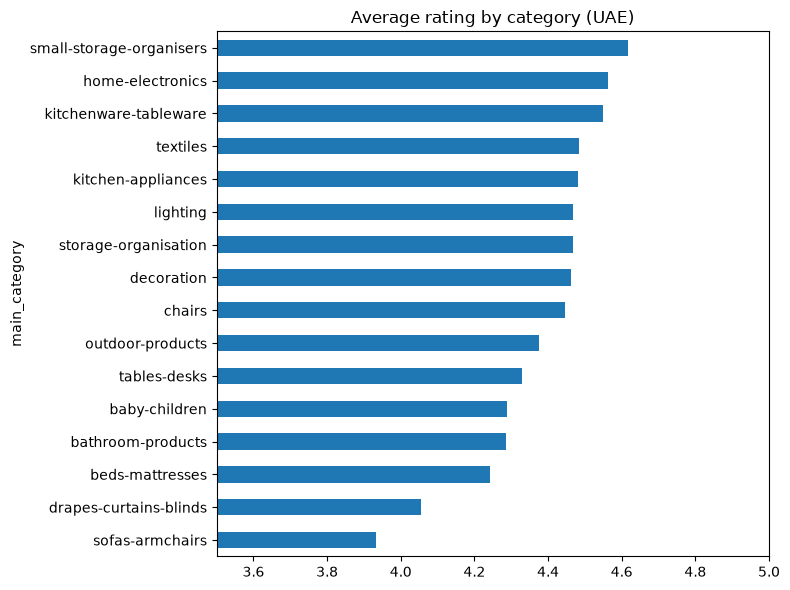

In [15]:
import matplotlib.pyplot as plt

cat.sort_values("avg_rating")["avg_rating"].plot(kind="barh", figsize=(8, 6), title="Average rating by category (UAE)")
plt.xlim(3.5, 5)
plt.tight_layout()
plt.show()

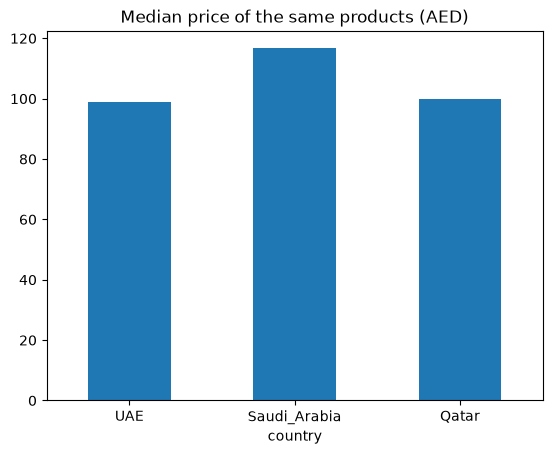

In [16]:
table[["UAE", "Saudi_Arabia", "Qatar"]].median().plot(kind="bar", title="Median price of the same products (AED)")
plt.xticks(rotation=0)
plt.show()

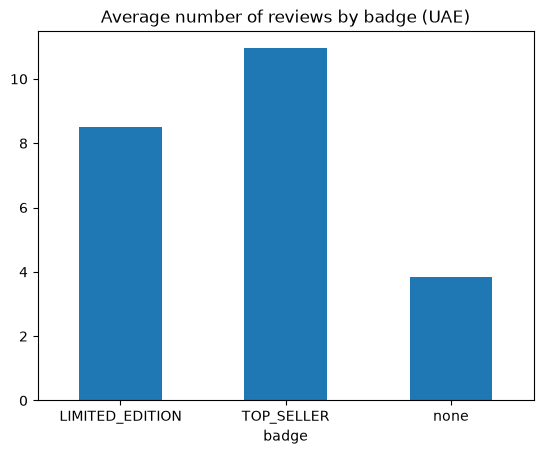

In [17]:
uae.groupby("badge")["product_rating_count"].mean().plot(kind="bar", title="Average number of reviews by badge (UAE)")
plt.xticks(rotation=0)
plt.show()

## Summary
- Sofas have the lowest rating in the UAE (3.93). Their reviews should be checked.
- The UAE is about 15% cheaper than Saudi Arabia for the same products.
- Top Sellers are popular (more reviews), not rated higher.
- Limitation: there are no sales numbers, so the number of reviews only shows popularity.